# 05 · Spatial hotspots: H3 grid + Getis-Ord Gi\* with FDR control

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryam843/uk-road-accident-analytics/blob/main/notebooks/05_spatial_hotspots.ipynb)

**Replaces** the original coursework's "K-Means hotspots" (k = 5 on coordinates), its folium
marker map and its weighted "risk index".

**Question:** where do killed-or-seriously-injured (KSI) collisions cluster in space more than
spatial randomness would produce, and is that pattern stable over time?

**Method**
1. Collisions 2015-2019 with valid coordinates (`coord_valid`; invalid ones are counted and
   dropped, never imputed).
2. Counts per **H3** hexagon: resolution 7 for Great Britain, resolution 8 for Greater London.
3. **Getis-Ord Gi\*** (`esda.G_Local(star=True)`) on KSI counts per hexagon, k = 6 nearest
   neighbour weights, 999 permutations, two-sided test, **Benjamini-Hochberg FDR at 0.05**.
   Only significant positive cells are called hotspots.
4. KSI **rate** per hexagon (only hexagons with at least 30 collisions) with Wilson 95%
   intervals, replacing the old risk index.
5. Stability: Gi\* run separately on 2015-2016 and 2018-2019; Jaccard overlap of hot cells.
6. The old method (K-Means, k = 5, raw coordinates) on the same data, for comparison.

**Results (this run):** 
- 646,694 collisions with valid coordinates (136 dropped) in 28,801 occupied resolution-7
  hexagons.
- **1,002 hot hexagons and 0 cold** at FDR 0.05. They are 3.5% of occupied hexagons but hold
  32.1% of KSI collisions (and 39.8% of all collisions). The Metropolitan Police area has 250 of
  them, West Midlands 101.
- Greater London at resolution 8: 180 hot hexagons of 2,326, forming one central block.
- KSI **rate**: 277 of the 4,287 hexagons with at least 30 collisions have a Wilson lower bound
  above the overall KSI share (0.1826). None of the top 15 by that bound is a count-based hot
  hexagon: places with many KSI collisions are not the places where a collision is most likely
  to be severe.
- Stability: Jaccard 0.603 between the hot sets of 2015-2016 (1,191) and 2018-2019 (893); 784
  hexagons are hot in both.
- The old K-Means "hotspots" are five regions that between them contain 100% of collisions.

In [1]:
# Setup: works from the repo root, from notebooks/, or on Google Colab.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/config.py").exists():
    if not Path("uk-road-accident-analytics").exists():
        !git clone -q https://github.com/maryam843/uk-road-accident-analytics.git
    %cd uk-road-accident-analytics
    %pip install -q -r requirements.txt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import clean, config, evaluate

config.setup_logging(logging.INFO)
evaluate.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = config.get_data_dir()
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
if not (PROCESSED / config.COLLISIONS_PARQUET).exists():
    # Fresh runtime (e.g. Colab): download (several GB) and clean. Takes a while, once.
    from src import download

    download.main([])
    clean.run()
print("DATA_DIR =", DATA_DIR)

import folium
import h3
from branca.colormap import LinearColormap
from folium.plugins import HeatMap
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch
from sklearn.cluster import KMeans

from src import spatial

YEARS = (2015, 2019)
GB_RES, LONDON_RES, K = 7, 8, 6
LONDON_FORCES = [1, 48]  # Metropolitan Police, City of London

DATA_DIR = data


## Data: 2015-2019 collisions with valid coordinates

In [3]:
COLS = ["collision_index", "collision_year", "latitude", "longitude", "coord_valid", "ksi",
        "collision_severity", "police_force", "police_force_label"]
coll = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET, columns=COLS)
coll = coll[coll["collision_year"].between(*YEARS)]
n_all, n_bad = len(coll), int((~coll["coord_valid"]).sum())
coll = coll[coll["coord_valid"]].copy()
coll["fatal"] = (coll["collision_severity"] == clean.SEVERITY_FATAL).astype(int)
coll["ksi"] = coll["ksi"].astype(int)
coll["cell"] = spatial.to_cells(coll["latitude"], coll["longitude"], GB_RES)
print(f"{n_all:,} collisions {YEARS[0]}-{YEARS[1]}; {n_bad:,} without valid coordinates dropped "
      f"({n_bad / n_all:.3%}); {len(coll):,} kept")
OVERALL_KSI = coll["ksi"].mean()
print(f"KSI collisions: {coll['ksi'].sum():,} (share {OVERALL_KSI:.4f}); fatal: {coll['fatal'].sum():,}")

646,830 collisions 2015-2019; 136 without valid coordinates dropped (0.021%); 646,694 kept
KSI collisions: 118,055 (share 0.1826); fatal: 8,315


## H3 grid
Resolution 7 hexagons (printed area below) keep GB-wide Gi\* tractable (tens of thousands
of cells) while staying small enough to separate towns. Only hexagons containing at least one
collision exist in the analysis: empty land and sea are outside the study area, so "cold"
means low relative to other places where collisions happen.

In [4]:
def aggregate(frame, cell_col="cell"):
    """Collisions, KSI and fatal counts per cell, the modal police force, and centroids."""
    agg = frame.groupby(cell_col).agg(collisions=("ksi", "size"), ksi=("ksi", "sum"),
                                      fatal=("fatal", "sum"))
    force = (frame.groupby([cell_col, "police_force_label"], observed=True).size()
             .rename("n").reset_index().sort_values("n", ascending=False)
             .drop_duplicates(cell_col).set_index(cell_col)["police_force_label"])
    agg["police_force"] = force.reindex(agg.index).astype(str)
    agg = agg.join(spatial.cell_centroids(agg.index))
    return agg


hexes = aggregate(coll)
xy = spatial.local_xy_km(hexes["lat"], hexes["lon"])
print(f"Resolution {GB_RES}: average hexagon area {h3.average_hexagon_area(GB_RES, 'km^2'):.2f} km^2")
print(f"{len(hexes):,} occupied hexagons; collisions per hexagon: median {hexes['collisions'].median():.0f}, "
      f"max {hexes['collisions'].max():,}; KSI per hexagon: median {hexes['ksi'].median():.0f}, "
      f"max {hexes['ksi'].max():,}")
print(f"Hexagons with at least 30 collisions: {(hexes['collisions'] >= 30).sum():,}")

Resolution 7: average hexagon area 5.16 km^2
28,801 occupied hexagons; collisions per hexagon: median 5, max 2,740; KSI per hexagon: median 1, max 374
Hexagons with at least 30 collisions: 4,287


## Getis-Ord Gi\* on KSI counts (GB, resolution 7)

- **Weights:** each hexagon's 6 nearest occupied hexagons (centroid distance in km), plus
  itself (`star=True`), row-standardised. With all neighbours present this is the hexagon's
  first ring.
- **Inference:** 999 conditional permutations give each cell's expected Gi\* and its spread
  under spatial randomness; `z_sim` standardises the observed value by them. The two-sided
  p-value is taken from `z_sim`, then **Benjamini-Hochberg** controls the false discovery rate
  at 0.05 across all hexagons. The pure permutation p-value (`p_sim`) cannot go below
  1/1000, which is too coarse for an FDR correction over this many cells; the count it
  would give is printed for transparency.
- **Hot** = significant and `z_sim` > 0; **cold** = significant and `z_sim` < 0.

In [5]:
from statsmodels.stats.multitest import multipletests

w6 = spatial.knn_weights(xy, K)
gi = spatial.gi_star(hexes["ksi"], w6, index=hexes.index)
hexes["gi_z"], hexes["gi_q"], hexes["cluster"] = gi["z_sim"], gi["q_bh"], gi["cluster"]
counts = hexes["cluster"].value_counts()
print(f"Significant at FDR 0.05: {counts.get('hot', 0):,} hot and {counts.get('cold', 0):,} cold hexagons "
      f"(of {len(hexes):,})")
p_sim_rejections = multipletests(gi["p_sim"], alpha=0.05, method="fdr_bh")[0]
print(f"For comparison, BH on the one-sided permutation p_sim would flag {p_sim_rejections.sum():,} cells")
hot = hexes[hexes["cluster"] == "hot"]
print(f"Hot hexagons hold {hot['ksi'].sum() / hexes['ksi'].sum():.1%} of KSI collisions and "
      f"{hot['collisions'].sum() / hexes['collisions'].sum():.1%} of all collisions, "
      f"on {len(hot) / len(hexes):.1%} of occupied hexagons")
by_force = (hot.groupby("police_force").agg(hot_hexagons=("ksi", "size"), ksi=("ksi", "sum"))
            .sort_values("hot_hexagons", ascending=False))
print("Hot hexagons by police force (top 10):")
display(by_force.head(10))

Significant at FDR 0.05: 1,002 hot and 0 cold hexagons (of 28,801)
For comparison, BH on the one-sided permutation p_sim would flag 0 cells
Hot hexagons hold 32.1% of KSI collisions and 39.8% of all collisions, on 3.5% of occupied hexagons
Hot hexagons by police force (top 10):


,hot_hexagons,ksi
police_force,,
Metropolitan Police,250,14741
West Midlands,101,3625
West Yorkshire,52,1652
South Yorkshire,49,1561
Greater Manchester,47,1301
Hampshire,45,1559
Sussex,43,1380
Lancashire,43,1249
Merseyside,38,1315


19:43:58 INFO src.evaluate: Saved figure reports/figures/05_gi_star_gb.png


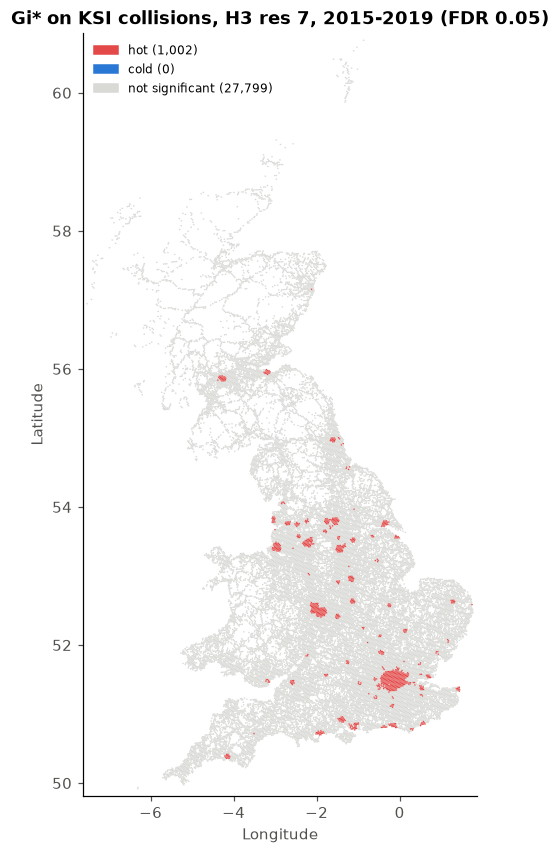

In [6]:
CLUSTER_COLOURS = {"hot": evaluate.PALETTE[7], "cold": evaluate.PALETTE[0], "not significant": "#d9d9d6"}


def hex_map(frame, ax, title):
    """Draw every hexagon, coloured by its Gi* class."""
    order = frame.sort_values("cluster", key=lambda s: s.map({"not significant": 0, "cold": 1, "hot": 2}))
    polys = [[(lon, lat) for lat, lon in h3.cell_to_boundary(c)] for c in order.index]
    ax.add_collection(PolyCollection(polys, facecolors=order["cluster"].map(CLUSTER_COLOURS),
                                     edgecolors="none"))
    ax.set_xlim(frame["lon"].min() - 0.1, frame["lon"].max() + 0.1)
    ax.set_ylim(frame["lat"].min() - 0.1, frame["lat"].max() + 0.1)
    ax.set_aspect(1 / np.cos(np.deg2rad(frame["lat"].mean())))
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(False)
    ax.set_title(title)
    n = frame["cluster"].value_counts()
    ax.legend(handles=[Patch(color=CLUSTER_COLOURS[c], label=f"{c} ({n.get(c, 0):,})")
                       for c in ["hot", "cold", "not significant"]], loc="upper left", fontsize=8)


fig, ax = plt.subplots(figsize=(7, 9))
hex_map(hexes, ax, f"Gi* on KSI collisions, H3 res {GB_RES}, 2015-2019 (FDR 0.05)")
evaluate.save_fig(fig, "05_gi_star_gb")
plt.show()

## Greater London at a finer resolution (H3 resolution 8)

Greater London = the Metropolitan Police and City of London force areas. Resolution 8
hexagons are about seven times smaller than resolution 7. Resolution 9 was tried during
design but leaves most hexagons with zero or one KSI collision over five years, so
resolution 8 is used.

London: 128,441 collisions in 2,326 res-8 hexagons (average area 0.74 km^2); KSI per hexagon median 4
Significant at FDR 0.05: 180 hot and 0 cold hexagons


19:43:59 INFO src.evaluate: Saved figure reports/figures/05_gi_star_london.png


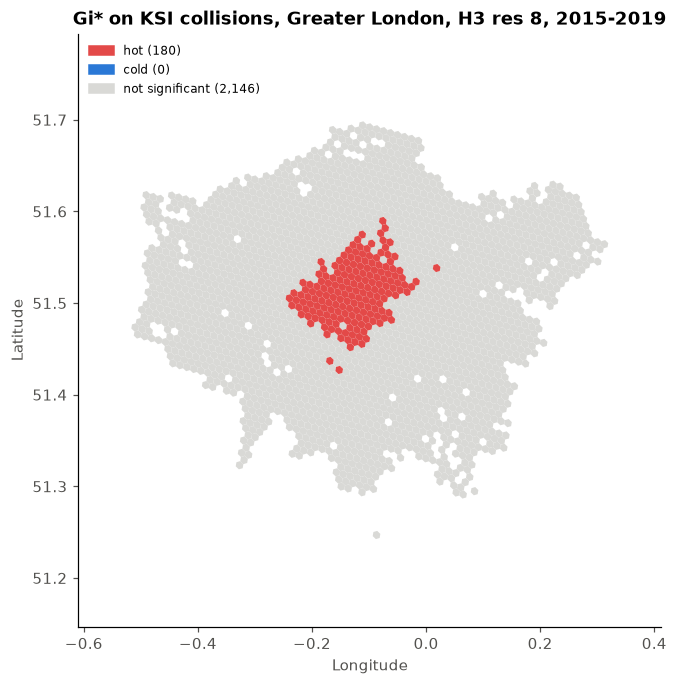

In [7]:
london = coll[coll["police_force"].isin(LONDON_FORCES)].copy()
london["cell8"] = spatial.to_cells(london["latitude"], london["longitude"], LONDON_RES)
lhex = aggregate(london, "cell8")
lgi = spatial.gi_star(lhex["ksi"], spatial.knn_weights(spatial.local_xy_km(lhex["lat"], lhex["lon"]), K),
                      index=lhex.index)
lhex["gi_z"], lhex["gi_q"], lhex["cluster"] = lgi["z_sim"], lgi["q_bh"], lgi["cluster"]
lc = lhex["cluster"].value_counts()
print(f"London: {len(london):,} collisions in {len(lhex):,} res-{LONDON_RES} hexagons "
      f"(average area {h3.average_hexagon_area(LONDON_RES, 'km^2'):.2f} km^2); KSI per hexagon median "
      f"{lhex['ksi'].median():.0f}")
print(f"Significant at FDR 0.05: {lc.get('hot', 0):,} hot and {lc.get('cold', 0):,} cold hexagons")
fig, ax = plt.subplots(figsize=(9, 7))
hex_map(lhex, ax, f"Gi* on KSI collisions, Greater London, H3 res {LONDON_RES}, 2015-2019")
evaluate.save_fig(fig, "05_gi_star_london")
plt.show()

## KSI rate per hexagon with Wilson intervals (replaces the old risk index)

The old risk index added up weighted columns, including raw latitude and longitude, so its
ranking partly reflected where a place is on the map. Here the measure is simply the share
of collisions in a hexagon that were KSI, shown only for hexagons with at least 30 collisions,
with a Wilson 95% interval. Hexagons are ranked by the **lower** bound of the interval, so a
high rate based on few collisions does not top the list.

In [8]:
rated = hexes[hexes["collisions"] >= 30].copy()
rated["ksi_rate"] = rated["ksi"] / rated["collisions"]
rated["wilson_low"], rated["wilson_high"] = evaluate.wilson_interval(rated["ksi"], rated["collisions"])
above = (rated["wilson_low"] > OVERALL_KSI).sum()
print(f"{len(rated):,} hexagons with >= 30 collisions; {above:,} have a Wilson lower bound above the "
      f"overall KSI share ({OVERALL_KSI:.4f})")
top15 = rated.sort_values("wilson_low", ascending=False).head(15)
display(top15[["police_force", "lat", "lon", "collisions", "ksi", "ksi_rate", "wilson_low", "wilson_high",
               "cluster"]].style.format({"lat": "{:.4f}", "lon": "{:.4f}", "ksi_rate": "{:.3f}",
                                         "wilson_low": "{:.3f}", "wilson_high": "{:.3f}"}))
print(f"Of these 15, {(top15['cluster'] == 'hot').sum()} are Gi* hot hexagons (count-based).")

4,287 hexagons with >= 30 collisions; 277 have a Wilson lower bound above the overall KSI share (0.1826)


,police_force,lat,lon,collisions,ksi,ksi_rate,wilson_low,wilson_high,cluster
cell,,,,,,,,,
87195885affffff,Gloucestershire,51.8330,-2.1006,31,17,0.548,0.378,0.708,not significant
8719420c5ffffff,South Yorkshire,53.4581,-1.4847,32,17,0.531,0.364,0.691,not significant
871942336ffffff,South Yorkshire,53.4170,-1.1823,35,18,0.514,0.356,0.670,not significant
871959069ffffff,Hampshire,50.7042,-1.2428,32,15,0.469,0.309,0.636,not significant
871946562ffffff,Cleveland,54.6525,-1.2272,56,24,0.429,0.308,0.559,not significant
87194e010ffffff,Essex,51.8910,0.5653,46,20,0.435,0.302,0.578,not significant
87194a19bffffff,Sussex,51.0081,-0.1326,33,15,0.455,0.298,0.620,not significant
871976bb2ffffff,Grampian,57.1379,-2.0970,137,51,0.372,0.296,0.456,not significant
87194e091ffffff,Essex,51.8645,0.3592,36,16,0.444,0.295,0.604,not significant


Of these 15, 0 are Gi* hot hexagons (count-based).


## Stability: 2015-2016 vs 2018-2019

Gi\* is rerun on each two-year period using the **same** hexagons and weights (cells empty in
one period count as 0). Caveat: police forces adopted injury-based severity reporting
(CRASH/COPA) at different times around 2016-2019, which raises recorded KSI in the forces that
switched. Part of any change between the periods can therefore be a recording effect.

In [9]:
period_hot = {}
for label, (y0, y1) in {"2015-2016": (2015, 2016), "2018-2019": (2018, 2019)}.items():
    ksi_p = (coll[coll["collision_year"].between(y0, y1)].groupby("cell")["ksi"].sum()
             .reindex(hexes.index, fill_value=0))
    res = spatial.gi_star(ksi_p, w6, index=hexes.index)
    period_hot[label] = set(res.index[res["cluster"] == "hot"])
    print(f"{label}: {ksi_p.sum():,} KSI collisions; {len(period_hot[label]):,} hot hexagons")
a, b = period_hot["2015-2016"], period_hot["2018-2019"]
full_hot = set(hot.index)
print(f"Hot in both periods: {len(a & b):,}; only 2015-2016: {len(a - b):,}; only 2018-2019: {len(b - a):,}")
print(f"Jaccard(2015-2016, 2018-2019) = {evaluate.jaccard(a, b):.3f}")
print(f"Jaccard with the 2015-2019 hot set: 2015-2016 {evaluate.jaccard(a, full_hot):.3f}, "
      f"2018-2019 {evaluate.jaccard(b, full_hot):.3f}")

2015-2016: 44,766 KSI collisions; 1,191 hot hexagons


2018-2019: 49,261 KSI collisions; 893 hot hexagons
Hot in both periods: 784; only 2015-2016: 407; only 2018-2019: 109
Jaccard(2015-2016, 2018-2019) = 0.603
Jaccard with the 2015-2019 hot set: 2015-2016 0.742, 2018-2019 0.806


## The old method: K-Means (k = 5) on raw coordinates

The original project ran K-Means with k = 5 on latitude and longitude and called the five
centroids "hotspots". The same is done here on the same collisions, for comparison.

,collisions,ksi,lat,lon,share_of_collisions,ksi_share,wilson_low,wilson_high,main_police_force,share_in_gi_hot_hexagons
kmeans,,,,,,,,,,
0,299505,50014,51.552,-0.124,46.3%,0.1670,0.1657,0.1683,Metropolitan Police,52.7%
1,112186,21547,53.715,-1.225,17.3%,0.1921,0.1898,0.1944,West Yorkshire,33.7%
2,69536,12957,51.181,-3.126,10.8%,0.1863,0.1835,0.1892,Devon and Cornwall,15.2%
3,39959,8915,55.965,-3.692,6.2%,0.2231,0.2190,0.2272,Strathclyde,17.4%
4,125508,24622,53.053,-2.325,19.4%,0.1962,0.1940,0.1984,West Midlands,35.6%


Collisions assigned to some K-Means 'hotspot': 100%


19:44:10 INFO src.evaluate: Saved figure reports/figures/05_kmeans_coordinates.png


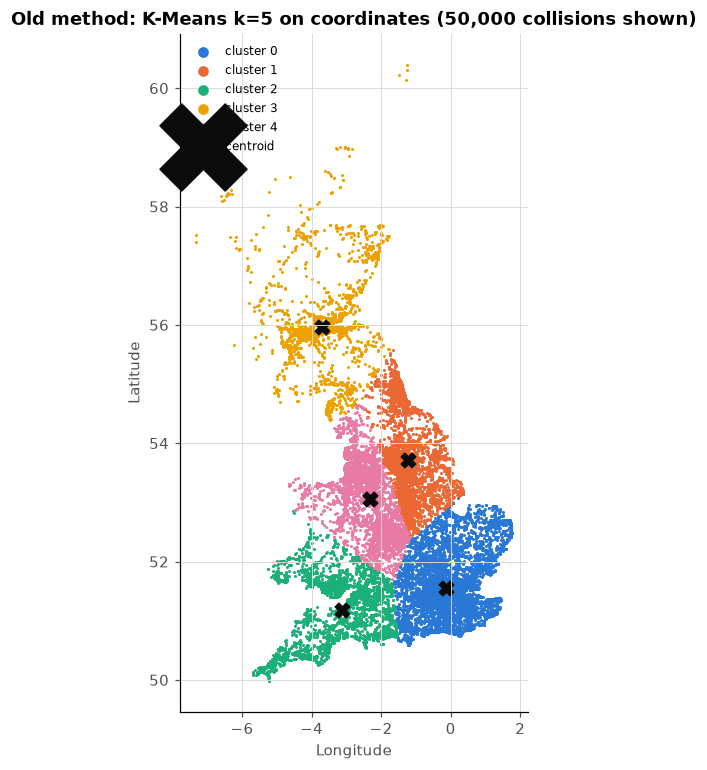

In [10]:
km = KMeans(n_clusters=5, n_init=10, random_state=config.RANDOM_STATE)
coll["kmeans"] = km.fit_predict(coll[["latitude", "longitude"]].to_numpy())
kprof = coll.groupby("kmeans").agg(collisions=("ksi", "size"), ksi=("ksi", "sum"),
                                   lat=("latitude", "mean"), lon=("longitude", "mean"))
kprof["share_of_collisions"] = kprof["collisions"] / len(coll)
kprof["ksi_share"] = kprof["ksi"] / kprof["collisions"]
kprof["wilson_low"], kprof["wilson_high"] = evaluate.wilson_interval(kprof["ksi"], kprof["collisions"])
kprof["main_police_force"] = (coll.groupby(["kmeans", "police_force_label"], observed=True).size()
                              .groupby(level=0).idxmax().map(lambda t: t[1]))
kprof["share_in_gi_hot_hexagons"] = coll["cell"].isin(hot.index).groupby(coll["kmeans"]).mean()
display(kprof.style.format({"lat": "{:.3f}", "lon": "{:.3f}", "share_of_collisions": "{:.1%}",
                            "share_in_gi_hot_hexagons": "{:.1%}",
                            "ksi_share": "{:.4f}", "wilson_low": "{:.4f}", "wilson_high": "{:.4f}"}))
print(f"Collisions assigned to some K-Means 'hotspot': {coll['kmeans'].notna().mean():.0%}")

fig, ax = plt.subplots(figsize=(6, 8))
sample = coll.sample(50_000, random_state=config.RANDOM_STATE)
for k in range(5):
    pts = sample[sample["kmeans"] == k]
    ax.scatter(pts["longitude"], pts["latitude"], s=1, color=evaluate.PALETTE[k], label=f"cluster {k}")
ax.scatter(kprof["lon"], kprof["lat"], marker="X", s=90, color="#0b0b0b", label="centroid")
ax.set_aspect(1 / np.cos(np.deg2rad(54)))
ax.set_title("Old method: K-Means k=5 on coordinates (50,000 collisions shown)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(markerscale=6, fontsize=8, loc="upper left")
evaluate.save_fig(fig, "05_kmeans_coordinates")
plt.show()

**Why K-Means on coordinates partitions space but does not find hotspots.** K-Means must put
every collision in one of k groups, so 100% of collisions end up in a "hotspot". Here the five
groups are simply regions: one around London and the South East (46.3% of collisions), and
others centred on Yorkshire, the Midlands/North West, the South West and Scotland. A centroid
is the average position of a region's collisions, not a place where collisions concentrate.
K-Means has no null model, so it cannot say whether any group is denser than chance, and k = 5
was a choice, not a finding. Raw degrees also distort distance (a degree of longitude is much
shorter than a degree of latitude in Great Britain). The KSI shares even run the other way:
the London group has the lowest KSI share (0.1670) and the Scottish group the highest
(0.2231). Gi\* instead compares each hexagon's neighbourhood with what spatial randomness
would produce and controls false discoveries across all hexagons.

## Interactive map: `reports/hotspot_map.html`

Layers: significant hot hexagons for GB (resolution 7) coloured by Gi\* z-score, significant
hot hexagons for Greater London (resolution 8, off by default), and a heat map of fatal
collisions 2015-2019. Static versions: `reports/figures/05_gi_star_gb.png`,
`05_gi_star_london.png` and `05_fatal_density.png`.

Saved reports/hotspot_map.html: 0.64 MB; 8,315 fatal collisions in the heat map


19:44:11 INFO src.evaluate: Saved figure reports/figures/05_fatal_density.png


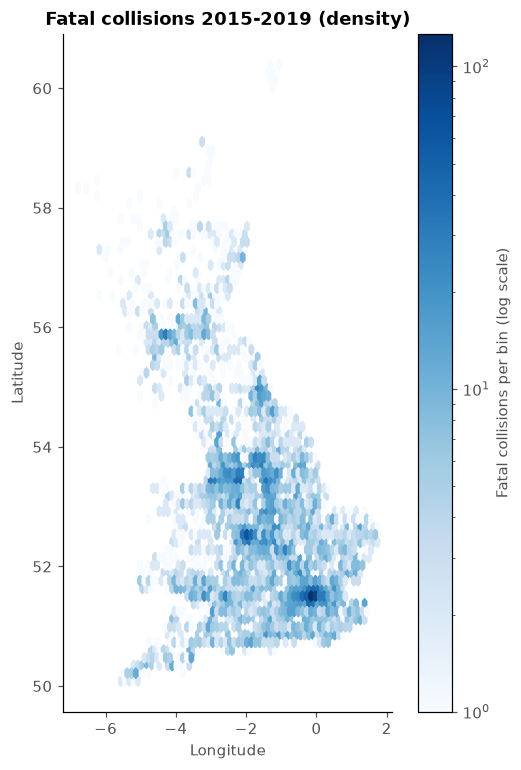

In [11]:
MAP_PATH = config.REPO_ROOT / "reports" / "hotspot_map.html"


def hot_layer(frame, name, show=True):
    hot_cells = frame[frame["cluster"] == "hot"]
    cmap = LinearColormap(["#fdd49e", "#fc8d59", "#d7301f", "#7f0000"],
                          vmin=float(hot_cells["gi_z"].min()), vmax=float(hot_cells["gi_z"].max()),
                          caption=f"Gi* z-score ({name})")
    features_ = [{"type": "Feature",
                  "geometry": {"type": "Polygon", "coordinates": [spatial.cell_boundary_lonlat(c)]},
                  "properties": {"collisions": int(r.collisions), "ksi": int(r.ksi),
                                 "z": round(float(r.gi_z), 2), "q": f"{r.gi_q:.1e}",
                                 "force": r.police_force}}
                 for c, r in hot_cells.iterrows()]
    layer = folium.GeoJson(
        {"type": "FeatureCollection", "features": features_}, name=name, show=show,
        style_function=lambda f: {"fillColor": cmap(f["properties"]["z"]), "color": "#52514e",
                                  "weight": 0.3, "fillOpacity": 0.75},
        tooltip=folium.GeoJsonTooltip(["force", "collisions", "ksi", "z", "q"],
                                      aliases=["Police force", "Collisions", "KSI", "Gi* z", "FDR q"]))
    return layer, cmap


m = folium.Map(location=[54.0, -2.5], zoom_start=6, tiles="OpenStreetMap")
gb_layer, gb_cmap = hot_layer(hexes, f"GB hot hexagons (res {GB_RES})")
gb_layer.add_to(m)
gb_cmap.add_to(m)
lon_layer, _ = hot_layer(lhex, f"London hot hexagons (res {LONDON_RES})", show=False)
lon_layer.add_to(m)
fatal_pts = coll.loc[coll["fatal"] == 1, ["latitude", "longitude"]].round(4).to_numpy().tolist()
HeatMap(fatal_pts, name="Fatal collisions 2015-2019 (heat map)", radius=7, blur=9,
        min_opacity=0.3).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save(MAP_PATH)
size = MAP_PATH.stat().st_size
assert size < 10 * 1024 * 1024, "map must stay under 10 MB"
print(f"Saved {MAP_PATH.relative_to(config.REPO_ROOT)}: {size / 1e6:.2f} MB; "
      f"{len(fatal_pts):,} fatal collisions in the heat map")

fig, ax = plt.subplots(figsize=(6, 8))
fat = coll[coll["fatal"] == 1]
hb = ax.hexbin(fat["longitude"], fat["latitude"], gridsize=70, bins="log", cmap=evaluate.SEQUENTIAL_CMAP,
               mincnt=1)
fig.colorbar(hb, ax=ax, label="Fatal collisions per bin (log scale)")
ax.set_aspect(1 / np.cos(np.deg2rad(54)))
ax.set_title("Fatal collisions 2015-2019 (density)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(False)
evaluate.save_fig(fig, "05_fatal_density")
plt.show()

## Reading the results


- **What a hotspot means here:** a hexagon whose neighbourhood has significantly more KSI
  collisions than spatial randomness would produce (Gi\*, FDR 0.05). Hot hexagons are
  concentrated in London and the big conurbations.
- **No cold spots** were found. KSI counts per hexagon are small (median 1) and cannot go
  below 0, so a low-count neighbourhood is never extreme enough to survive the FDR correction.
- **Counts follow traffic.** Hot hexagons hold 39.8% of all collisions but 32.1% of KSI
  collisions, so a collision in a hot hexagon is on average *less* likely to be KSI. The
  highest KSI rates are in low-volume hexagons that are not count hotspots. Counts are not
  divided by traffic or road length, so a hotspot means many reported KSI collisions, not a
  higher risk per journey.
- **Stability is moderate** (Jaccard 0.603), and part of the change between periods can come
  from forces switching to injury-based severity reporting at different times.
- Gi\* describes where collisions cluster. It does not explain why, and it is not causal.

## Added evaluation: exposure check and weight-matrix sensitivity

**Exposure.** Hexagons with more traffic have more collisions of every kind, so they also have
more KSI collisions. A count-based hotspot can simply be a busy place. Two checks:
1. How closely KSI counts follow total collision counts across hexagons (Spearman), and how
   many count-based hot hexagons are among the busiest 10% of hexagons.
2. Gi\* on the **KSI share** of collisions (hexagons with at least 30 collisions only, k = 6
   nearest such hexagons), which removes volume from the measure. How many count-based hot
   hexagons are also share-based hot hexagons?

**Weights.** Gi\* on KSI counts is rerun with k = 12 neighbours instead of 6, and the hot
sets are compared (Jaccard).

Spearman correlation of collisions and KSI collisions across 28,801 hexagons: 0.825
Count-based hot hexagons among the busiest 10% of hexagons (>= 47 collisions): 936 of 1,002
KSI share inside count-based hot hexagons 0.1472 vs elsewhere 0.2059


Gi* on KSI share (4,287 hexagons with >= 30 collisions): 50 hot, 19 cold
Count-based hot hexagons with >= 30 collisions: 967; also share-based hot: 8; Jaccard 0.008
Count-based hot hexagons by share-based class: {'not significant': 957, 'hot': 8, 'cold': 2}
Share-based hot hexagons by police force (top 5): {'South Yorkshire': 13, 'Hampshire': 13, 'Grampian': 9, 'Sussex': 5, 'Lancashire': 3}


Gi* on KSI counts with k = 12: 1,587 hot, 0 cold; hot in both k = 6 and k = 12: 989; Jaccard(k=6, k=12) = 0.618


19:44:17 INFO src.evaluate: Saved figure reports/figures/05_gi_star_ksi_share.png


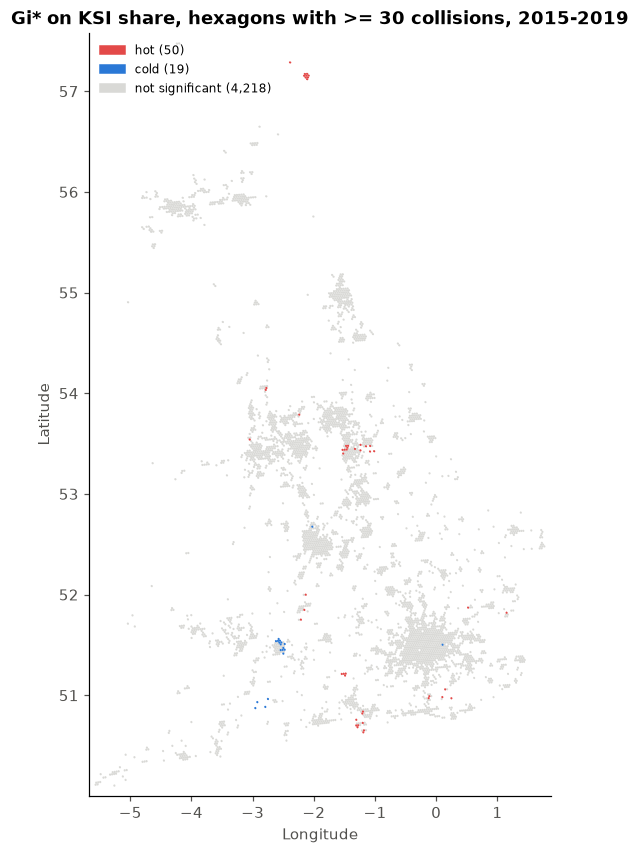

In [12]:
from scipy.stats import spearmanr

rho = spearmanr(hexes["collisions"], hexes["ksi"]).statistic
busy = hexes["collisions"] >= hexes["collisions"].quantile(0.9)
count_hot = set(hexes.index[hexes["cluster"] == "hot"])
print(f"Spearman correlation of collisions and KSI collisions across {len(hexes):,} hexagons: {rho:.3f}")
print(f"Count-based hot hexagons among the busiest 10% of hexagons (>= {hexes['collisions'].quantile(0.9):.0f} "
      f"collisions): {len(count_hot & set(hexes.index[busy])):,} of {len(count_hot):,}")
print(f"KSI share inside count-based hot hexagons {hot['ksi'].sum() / hot['collisions'].sum():.4f} vs "
      f"elsewhere {hexes.loc[hexes['cluster'] != 'hot', 'ksi'].sum() / hexes.loc[hexes['cluster'] != 'hot', 'collisions'].sum():.4f}")

share_gi = spatial.gi_star(rated["ksi_rate"],
                           spatial.knn_weights(spatial.local_xy_km(rated["lat"], rated["lon"]), K), index=rated.index)
rated["share_cluster"] = share_gi["cluster"]
share_hot = set(rated.index[rated["share_cluster"] == "hot"])
count_hot_rated = count_hot & set(rated.index)
sc = rated["share_cluster"].value_counts()
print(f"Gi* on KSI share ({len(rated):,} hexagons with >= 30 collisions): {sc.get('hot', 0):,} hot, "
      f"{sc.get('cold', 0):,} cold")
print(f"Count-based hot hexagons with >= 30 collisions: {len(count_hot_rated):,}; also share-based hot: "
      f"{len(count_hot_rated & share_hot):,}; Jaccard {evaluate.jaccard(count_hot_rated, share_hot):.3f}")
print("Count-based hot hexagons by share-based class:",
      rated.loc[list(count_hot_rated), "share_cluster"].value_counts().to_dict())
print("Share-based hot hexagons by police force (top 5):",
      rated.loc[list(share_hot), "police_force"].value_counts().head(5).to_dict())

gi12 = spatial.gi_star(hexes["ksi"], spatial.knn_weights(xy, 12), index=hexes.index)
hot12 = set(hexes.index[gi12["cluster"] == "hot"])
print(f"Gi* on KSI counts with k = 12: {len(hot12):,} hot, {(gi12['cluster'] == 'cold').sum():,} cold; "
      f"hot in both k = 6 and k = 12: {len(hot12 & count_hot):,}; Jaccard(k=6, k=12) = {evaluate.jaccard(count_hot, hot12):.3f}")

rated_map = rated.assign(cluster=rated["share_cluster"])
fig, ax = plt.subplots(figsize=(7, 9))
hex_map(rated_map, ax, "Gi* on KSI share, hexagons with >= 30 collisions, 2015-2019")
evaluate.save_fig(fig, "05_gi_star_ksi_share")
plt.show()

**Result: count hotspots are mostly busy places.** KSI counts follow total collision counts
closely (Spearman 0.825 across 28,801 hexagons), and 936 of the 1,002 count-based hot hexagons
are among the busiest 10% of hexagons (at least 47 collisions). Inside the hot hexagons the KSI
share is 0.1472, against 0.2059 elsewhere. Gi\* on the KSI **share** finds 50 hot and 19 cold
hexagons among the 4,287 with at least 30 collisions, led by South Yorkshire, Hampshire and
Grampian. Only 8 of the 967 count-based hot hexagons with at least 30 collisions are also
share-based hot hexagons (Jaccard 0.008); 957 are not significant on share and 2 are
share-based cold. Both views are useful: counts show where KSI collisions pile up (where to
put resources), shares show where a collision tends to be worse. Neither is a risk per
vehicle-kilometre, which would need traffic data.

**Weights.** With k = 12 neighbours Gi\* finds 1,587 hot hexagons instead of 1,002; 989 are hot
under both (Jaccard 0.618). A larger neighbourhood smooths more and spreads hot areas outwards.
The core is stable (989 of the 1,002 k = 6 hot hexagons stay hot), but the exact edge of a
hotspot depends on the weight matrix.